# Winter Road Safety in Great Britain: What Makes an Accident Severe?

**Author:** Carolina Donato · [LinkedIn](https://www.linkedin.com/in/carolina-donato/) · [GitHub](https://github.com/CarolinaVDonato)

This notebook analyses every police-reported road collision in Great Britain from January to March 2023 to answer three questions:

1. Do **weather conditions** affect how severe an accident is?
2. Do **road surface conditions**, such as wet or icy roads, lead to more serious accidents?
3. **When** are accidents most likely to happen, by time of day and day of the week?

**Data:** [Department for Transport, Road Safety Data 2023](https://www.data.gov.uk/dataset/cb7ae6f0-4be6-4935-9277-47e5ce24a11f/road-safety-data) (Open Government Licence).

**Contents**
1. Setup
2. Loading and cleaning the data
3. Overview
4. Weather and severity
5. Road surface and severity
6. Statistical testing
7. When accidents happen
8. Vehicles involved
9. Where accidents happen (interactive map)
10. Summary, limitations and recommendations

## 1. Setup

In [1]:
import os
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import folium
from folium.plugins import HeatMap
from scipy import stats

# Charts render as static images so they display on GitHub.
# For interactive charts, use "notebook" (Jupyter) or "colab" (Google Colab).
pio.renderers.default = "png"
pio.templates.default = "plotly_white"

DATA_PATH = "data/dft-road-casualty-statistics-collision-2023.csv"
os.makedirs("images", exist_ok=True)

# Labels from the DfT data guide
SEVERITY = {1: "Fatal", 2: "Serious", 3: "Slight"}
WEATHER = {
    1: "Fine", 2: "Rain", 3: "Snow",
    4: "Fine + high winds", 5: "Rain + high winds", 6: "Snow + high winds",
    7: "Fog or mist", 8: "Other", 9: "Unknown", -1: "Missing",
}
SURFACE = {
    1: "Dry", 2: "Wet/Damp", 3: "Snow", 4: "Frost/Ice", 5: "Flood",
    6: "Oil or diesel", 7: "Mud", 9: "Unknown", -1: "Missing",
}
UNINFORMATIVE = ["Other", "Unknown", "Missing"]

SEVERITY_ORDER = ["Slight", "Serious", "Fatal"]
SEVERITY_COLOURS = {"Slight": "#fdb863", "Serious": "#e66101", "Fatal": "#5e3c99"}  # colour-blind safe
ACCENT = "#5e3c99"
DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def save(fig, name, width=1000, height=520):
    """Show a chart and save a PNG copy to images/."""
    fig.update_layout(width=width, height=height, title_x=0.5, font=dict(size=13))
    fig.write_image(f"images/{name}.png", scale=2)
    fig.show()

## 2. Loading and cleaning the data

The raw file contains every collision recorded in 2023. Dates are stored as **DD/MM/YYYY**, so they must be parsed day-first. Parsing them month-first silently turns every date after the 12th of the month into a missing value. An earlier version of this project made that mistake and lost 59% of the winter records.

In [2]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Collisions in 2023: {len(raw):,}")

raw["date"] = pd.to_datetime(raw["date"], format="%d/%m/%Y")
assert raw["date"].notna().all(), "Some dates failed to parse"

df = raw[raw["date"].dt.month.isin([1, 2, 3])].copy()

df["severity"] = df["accident_severity"].map(SEVERITY)
df["weather"] = df["weather_conditions"].map(WEATHER)
df["surface"] = df["road_surface_conditions"].map(SURFACE)
df["serious_or_fatal"] = df["accident_severity"] <= 2
df["fatal"] = df["accident_severity"] == 1
df["hour"] = pd.to_datetime(df["time"], format="%H:%M", errors="coerce").dt.hour
df["day"] = df["date"].dt.day_name()
df["month"] = df["date"].dt.month_name()

print(f"Collisions from January to March 2023: {len(df):,}")
print(f"Date range: {df['date'].min():%d %b %Y} to {df['date'].max():%d %b %Y}")

Collisions in 2023: 104,258
Collisions from January to March 2023: 24,495
Date range: 01 Jan 2023 to 31 Mar 2023


### Data quality checks

In [3]:
quality = pd.DataFrame({
    "unlabelled weather code": [df["weather"].isna().sum()],
    "weather Other/Unknown/Missing": [df["weather"].isin(UNINFORMATIVE).sum()],
    "surface Unknown/Missing": [df["surface"].isin(UNINFORMATIVE).sum()],
    "missing time": [df["hour"].isna().sum()],
    "missing coordinates": [df[["latitude", "longitude"]].isna().any(axis=1).sum()],
    "duplicate accident_index": [df["accident_index"].duplicated().sum()],
}, index=["rows"]).T
quality["% of records"] = (quality["rows"] / len(df) * 100).round(2)
quality

,rows,% of records
unlabelled weather code,0,0.00
weather Other/Unknown/Missing,1724,7.04
surface Unknown/Missing,569,2.32
missing time,0,0.00
missing coordinates,2,0.01
duplicate accident_index,0,0.00


Data quality is good: every code maps to a label, there are no duplicates, and almost every record has a time and location. About 7% of records have an uninformative weather code ("Other", "Unknown" or missing). These are kept for the counts but excluded from the statistical tests.

In [4]:
df.to_csv("data/winter_data.csv", index=False)
print(df.groupby("month", sort=False).size().rename("collisions"))

month
January     8754
February    7558
March       8183
Name: collisions, dtype: int64


## 3. Overview

In [5]:
overview = (df["severity"].value_counts().reindex(SEVERITY_ORDER).to_frame("collisions"))
overview["% of total"] = (overview["collisions"] / len(df) * 100).round(1)
overview

,collisions,% of total
severity,,
Slight,19051,77.8
Serious,5124,20.9
Fatal,320,1.3


Most collisions are slight (78%), and just over 1 in 5 are serious or fatal. Because conditions such as fine weather and dry roads are far more common than others, **raw counts mostly reflect how often a condition occurs**. To compare severity fairly, the rest of the notebook focuses on **rates**: the share of collisions in each condition that were serious or fatal, and the share that were fatal.

In [6]:
def wilson_ci(successes, n, z=1.96):
    """95% Wilson confidence interval for a proportion, in percent."""
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (centre - half) * 100, (centre + half) * 100

def severity_rates(data, by, min_n=100):
    """Serious-or-fatal and fatal rates (with 95% CIs) for each level of `by`."""
    g = data.groupby(by).agg(collisions=("fatal", "size"),
                             serious_or_fatal=("serious_or_fatal", "sum"),
                             fatal=("fatal", "sum"))
    g = g[g["collisions"] >= min_n].copy()
    g["serious_or_fatal_%"] = (g["serious_or_fatal"] / g["collisions"] * 100).round(1)
    g["fatal_%"] = (g["fatal"] / g["collisions"] * 100).round(2)
    lo, hi = wilson_ci(g["fatal"], g["collisions"])
    g["fatal_%_95ci"] = [f"{a:.2f}–{b:.2f}" for a, b in zip(lo, hi)]
    g["fatal_ci_low"], g["fatal_ci_high"] = lo, hi
    return g.sort_values("collisions", ascending=False)

## 4. Weather and severity

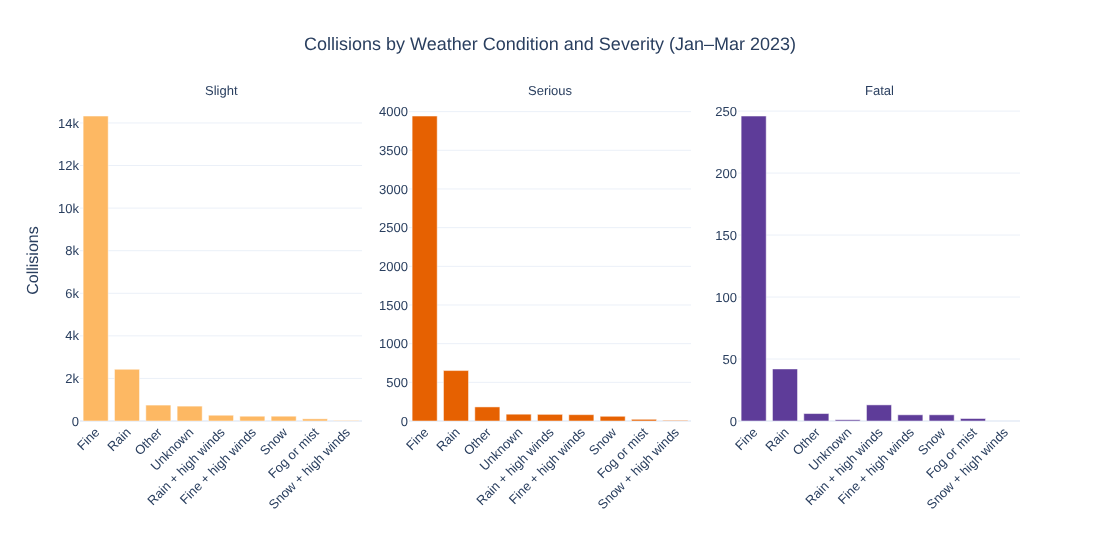

In [7]:
weather_counts = (df.groupby(["weather", "severity"]).size().reset_index(name="collisions"))
weather_order = df["weather"].value_counts().index.tolist()

fig = px.bar(weather_counts, x="weather", y="collisions", color="severity",
             facet_col="severity", facet_col_spacing=0.05,
             category_orders={"severity": SEVERITY_ORDER, "weather": weather_order},
             color_discrete_map=SEVERITY_COLOURS,
             title="Collisions by Weather Condition and Severity (Jan–Mar 2023)",
             labels={"weather": "", "collisions": "Collisions"})
fig.update_yaxes(matches=None, showticklabels=True)
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
fig.update_xaxes(tickangle=-45)
fig.update_layout(showlegend=False)
save(fig, "weather_by_severity", width=1100, height=550)

This chart redoes the faceted ggplot2 chart from the original R version. Each panel has its own scale, so the *shape* of each panel can be compared. The three shapes are almost identical: fine weather dominates every severity level, with rain second.

In [8]:
weather_rates = severity_rates(df, "weather")
weather_rates.drop(columns=["fatal_ci_low", "fatal_ci_high"])

,collisions,serious_or_fatal,fatal,serious_or_fatal_%,fatal_%,fatal_%_95ci
weather,,,,,,
Fine,18514,4189,246,22.6,1.33,1.17–1.50
Rain,3123,694,42,22.2,1.34,1.00–1.81
Other,936,188,6,20.1,0.64,0.29–1.39
Unknown,788,89,1,11.3,0.13,0.02–0.72
Rain + high winds,370,99,13,26.8,3.51,2.06–5.92
Fine + high winds,312,87,5,27.9,1.60,0.69–3.70
Snow,292,66,5,22.6,1.71,0.73–3.95
Fog or mist,126,24,2,19.0,1.59,0.44–5.60


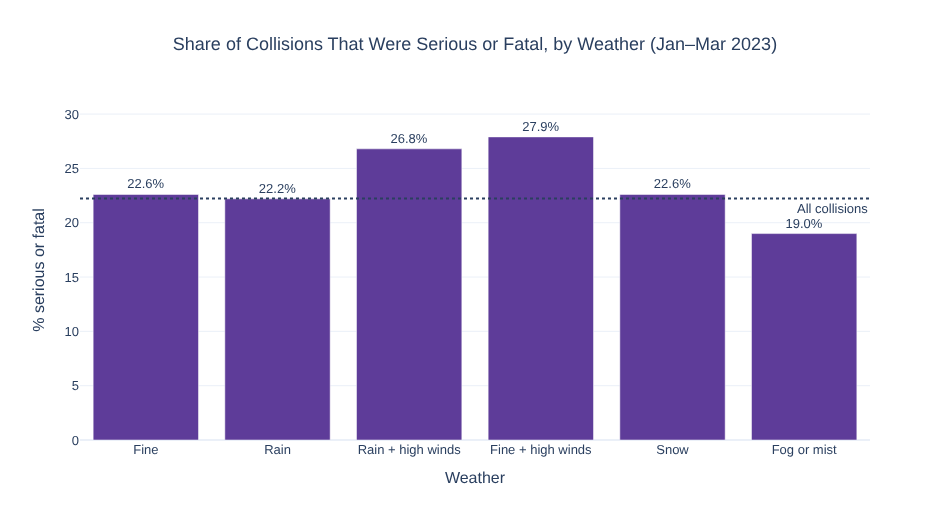

In [9]:
plot = weather_rates.drop(index=[w for w in UNINFORMATIVE if w in weather_rates.index]).reset_index()
fig = px.bar(plot, x="weather", y="serious_or_fatal_%", text="serious_or_fatal_%",
             title="Share of Collisions That Were Serious or Fatal, by Weather (Jan–Mar 2023)",
             labels={"weather": "Weather", "serious_or_fatal_%": "% serious or fatal"},
             color_discrete_sequence=[ACCENT])
fig.add_hline(y=df["serious_or_fatal"].mean() * 100, line_dash="dot",
              annotation_text="All collisions", annotation_position="bottom right")
fig.update_traces(texttemplate="%{text:.1f}%", textposition="outside")
save(fig, "severity_rate_by_weather", width=950)

**Findings**

* Rain without high winds has the **same severity profile as fine weather**: about 22% of collisions were serious or fatal in both.
* Fine or rainy weather with high winds shows higher rates (about 27–28%), but these two conditions account for fewer than 700 collisions between them, so the estimates are uncertain.
* Weather categories with fewer than 100 collisions (snow with high winds) are left out of the rate table, because their rates would be too unreliable.

## 5. Road surface and severity

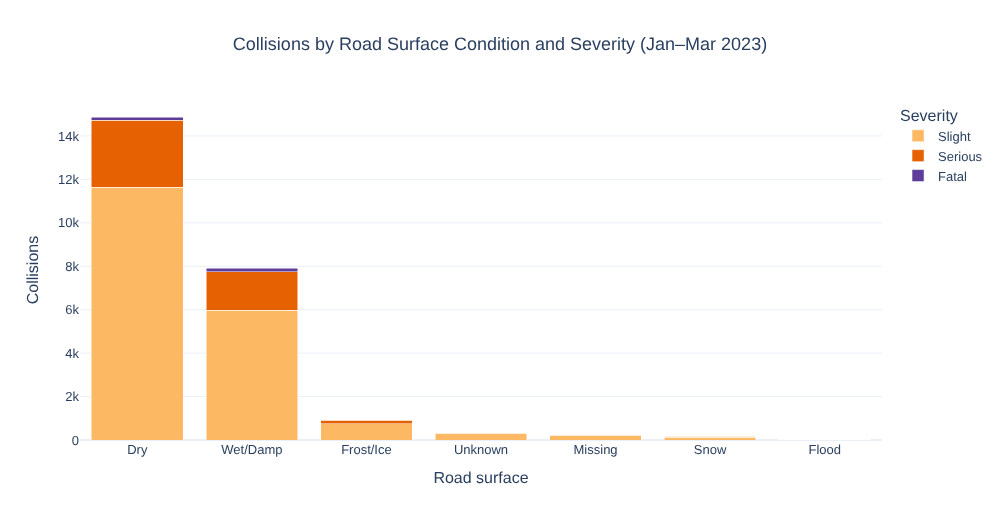

In [10]:
surface_counts = df.groupby(["surface", "severity"]).size().reset_index(name="collisions")
surface_order = df["surface"].value_counts().index.tolist()

fig = px.bar(surface_counts, x="surface", y="collisions", color="severity", barmode="stack",
             category_orders={"severity": SEVERITY_ORDER, "surface": surface_order},
             color_discrete_map=SEVERITY_COLOURS,
             title="Collisions by Road Surface Condition and Severity (Jan–Mar 2023)",
             labels={"surface": "Road surface", "collisions": "Collisions", "severity": "Severity"})
save(fig, "surface_by_severity")

This redoes the stacked ggplot2 chart from the original R version. Dry and wet roads account for 93% of collisions.

In [11]:
surface_rates = severity_rates(df, "surface")
surface_rates.drop(columns=["fatal_ci_low", "fatal_ci_high"])

,collisions,serious_or_fatal,fatal,serious_or_fatal_%,fatal_%,fatal_%_95ci
surface,,,,,,
Dry,14873,3224,152,21.7,1.02,0.87–1.20
Wet/Damp,7912,1931,155,24.4,1.96,1.68–2.29
Frost/Ice,931,191,10,20.5,1.07,0.58–1.97
Unknown,330,28,0,8.5,0.00,0.00–1.15
Missing,239,23,0,9.6,0.00,0.00–1.58
Snow,178,41,1,23.0,0.56,0.10–3.11


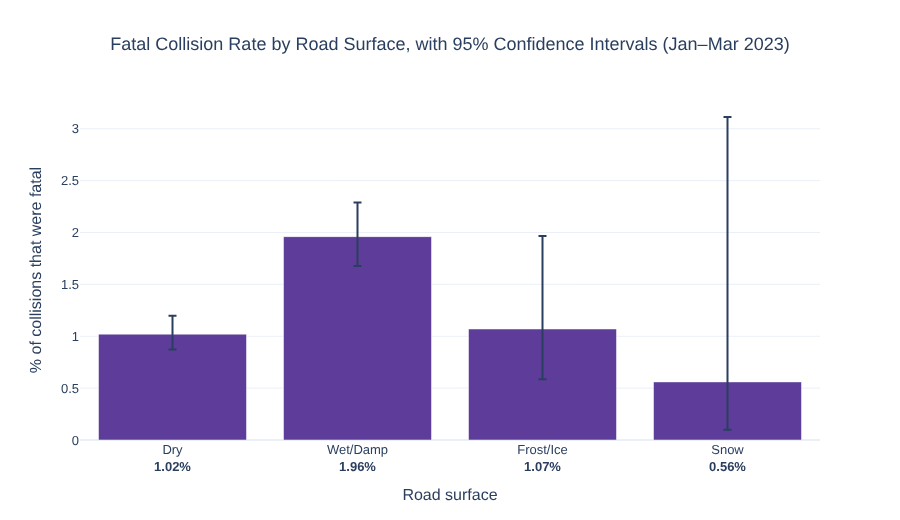

In [12]:
plot = surface_rates.loc[["Dry", "Wet/Damp", "Frost/Ice", "Snow"]].reset_index()
plot["label"] = plot["surface"] + "<br><b>" + plot["fatal_%"].map("{:.2f}%".format) + "</b>"
fig = px.bar(plot, x="label", y="fatal_%",
             error_y=plot["fatal_ci_high"] - plot["fatal_%"],
             error_y_minus=plot["fatal_%"] - plot["fatal_ci_low"],
             title="Fatal Collision Rate by Road Surface, with 95% Confidence Intervals (Jan–Mar 2023)",
             labels={"label": "Road surface", "fatal_%": "% of collisions that were fatal"},
             color_discrete_sequence=[ACCENT])
save(fig, "fatal_rate_by_surface", width=900)

In [13]:
dry, wet = surface_rates.loc["Dry"], surface_rates.loc["Wet/Damp"]
table = [[wet["fatal"], wet["collisions"] - wet["fatal"]],
         [dry["fatal"], dry["collisions"] - dry["fatal"]]]
odds_ratio, p_fisher = stats.fisher_exact(table)
print(f"Fatal rate on wet/damp roads: {wet['fatal_%']:.2f}% ({int(wet['fatal'])} of {int(wet['collisions']):,})")
print(f"Fatal rate on dry roads:      {dry['fatal_%']:.2f}% ({int(dry['fatal'])} of {int(dry['collisions']):,})")
print(f"Relative risk: {wet['fatal_%'] / dry['fatal_%']:.2f}x   Fisher's exact test p = {p_fisher:.1e}")

Fatal rate on wet/damp roads: 1.96% (155 of 7,912)
Fatal rate on dry roads:      1.02% (152 of 14,873)
Relative risk: 1.92x   Fisher's exact test p = 1.5e-08


**Findings**

* This is the clearest result in the project. **Collisions on wet or damp roads were almost twice as likely to be fatal as those on dry roads** (1.96% vs 1.02%), and the confidence intervals do not overlap.
* The serious-or-fatal rate is also higher on wet roads (24.4% vs 21.7%).
* Frost/ice and snow are **not** associated with more severe collisions. One plausible explanation is that drivers visibly slow down on icy or snowy roads, but wet roads don't feel as dangerous.

## 6. Statistical testing

Chi-squared tests of independence check whether severity is associated with weather and with road surface. Fatal collisions are too rare to test on their own across every category, so severity is grouped into **slight** vs **serious or fatal** (the standard "KSI" measure used in UK road safety). Fatal collisions on wet vs dry roads were already compared directly with Fisher's exact test in section 5. Uninformative categories are excluded, and the output checks that every expected cell count is at least 5. **Cramér's V** measures the strength of each association (0 = none, 1 = perfect), because with over 20,000 records even tiny effects can be statistically significant.

In [14]:
def chi_square(data, col, min_n=100):
    keep = data[~data[col].isin(UNINFORMATIVE)]
    counts = keep[col].value_counts()
    keep = keep[keep[col].isin(counts[counts >= min_n].index)]
    outcome = keep["serious_or_fatal"].map({False: "Slight", True: "Serious or fatal"})
    table = pd.crosstab(keep[col], outcome)[["Slight", "Serious or fatal"]]
    chi2, p, dof, expected = stats.chi2_contingency(table)
    v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
    residuals = (table - expected) / np.sqrt(expected)
    return table, residuals, dict(chi2=round(chi2, 1), dof=dof, p=p, cramers_v=round(v, 3),
                                  min_expected=round(expected.min(), 1))

weather_table, weather_resid, weather_test = chi_square(df, "weather")
surface_table, surface_resid, surface_test = chi_square(df, "surface")
pd.DataFrame({"Weather vs severity": weather_test, "Road surface vs severity": surface_test}).T

,chi2,dof,p,cramers_v,min_expected
Weather vs severity,9.7,5.0,0.084993,0.021,28.6
Road surface vs severity,24.3,3.0,0.000021,0.032,40.1


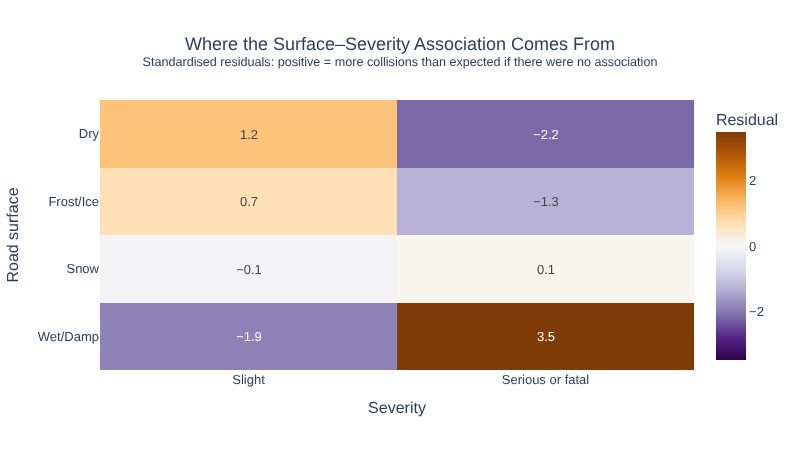

In [15]:
fig = px.imshow(surface_resid.round(1), text_auto=True, color_continuous_scale="PuOr_r",
                color_continuous_midpoint=0, aspect="auto",
                title="Where the Surface–Severity Association Comes From<br>"
                      "<sup>Standardised residuals: positive = more collisions than expected if there were no association</sup>",
                labels=dict(x="Severity", y="Road surface", color="Residual"))
save(fig, "surface_residuals", width=800, height=450)

**Findings**

* **Road surface** is significantly associated with severity (χ² = 24.3, p < 0.001), but the effect is small (Cramér's V = 0.03).
* The residuals show where the association comes from: **wet/damp roads have more serious or fatal collisions than expected**, and dry roads have fewer.
* **Weather** is **not** significantly associated with severity (χ² = 9.7, p ≈ 0.08), and the effect size is negligible. On its own, it tells us very little about how severe a collision will be.

## 7. When accidents happen

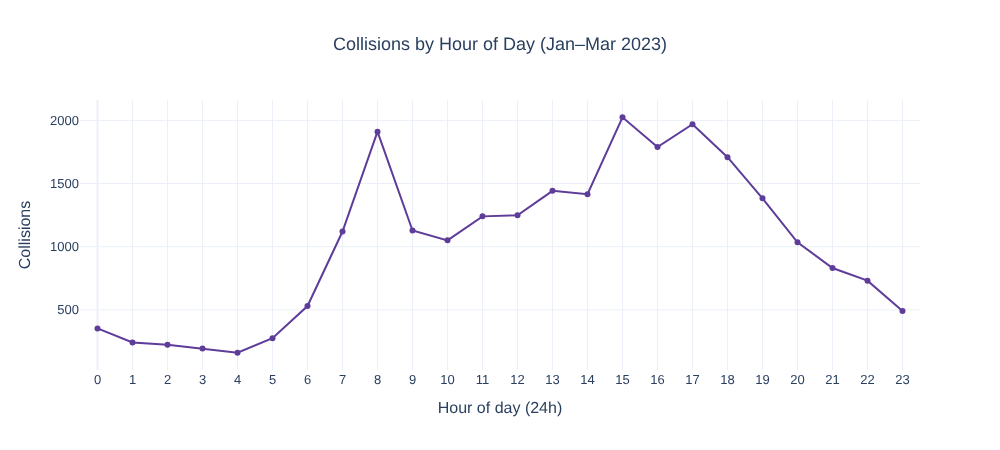

,hour,collisions
15,15,2025
17,17,1970
8,8,1911


In [16]:
hourly = df.dropna(subset=["hour"]).groupby("hour").size().reset_index(name="collisions")
fig = px.line(hourly, x="hour", y="collisions", markers=True,
              title="Collisions by Hour of Day (Jan–Mar 2023)",
              labels={"hour": "Hour of day (24h)", "collisions": "Collisions"},
              color_discrete_sequence=[ACCENT])
fig.update_xaxes(tickmode="linear", dtick=1, range=[-0.5, 23.5])
save(fig, "collisions_by_hour", width=1000, height=450)
hourly.nlargest(3, "collisions")

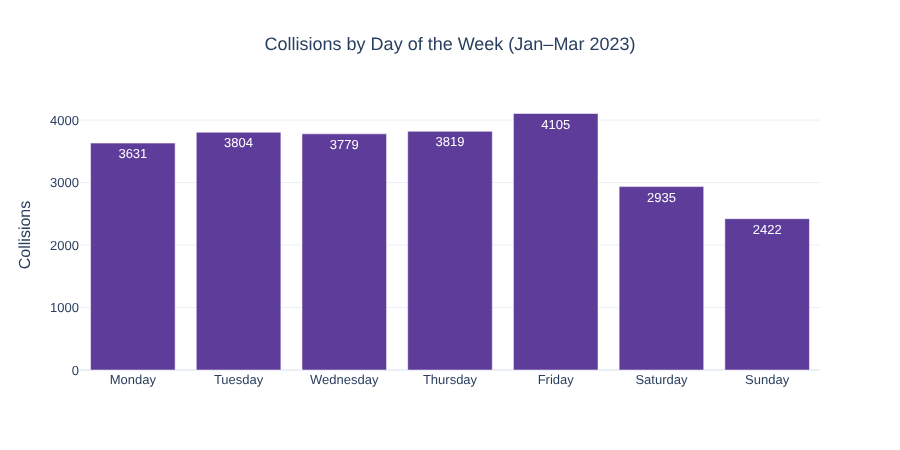

In [17]:
daily = df.groupby("day").size().reindex(DAY_ORDER).reset_index(name="collisions")
fig = px.bar(daily, x="day", y="collisions", text="collisions",
             title="Collisions by Day of the Week (Jan–Mar 2023)",
             labels={"day": "", "collisions": "Collisions"}, color_discrete_sequence=[ACCENT])
save(fig, "collisions_by_day", width=900, height=450)

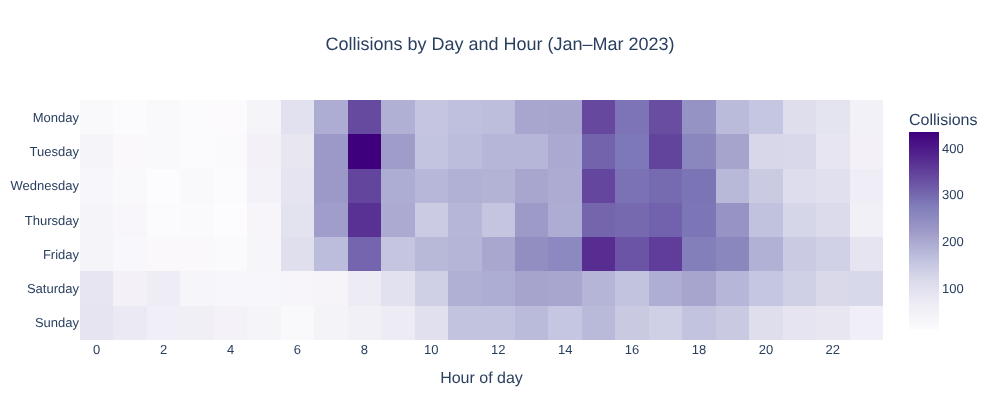

In [18]:
heat = (df.dropna(subset=["hour"]).pivot_table(index="day", columns="hour", values="fatal",
                                                aggfunc="size", fill_value=0).reindex(DAY_ORDER))
fig = px.imshow(heat, color_continuous_scale="Purples", aspect="auto",
                title="Collisions by Day and Hour (Jan–Mar 2023)",
                labels=dict(x="Hour of day", y="", color="Collisions"))
fig.update_xaxes(dtick=2)
save(fig, "collisions_day_hour", width=1000, height=420)

**Findings**

* Collisions peak at **3pm** (the school run), **5pm** and **8am** (commuting).
* **Friday** is the busiest day and **Sunday** the quietest.
* The heatmap shows that the weekday peaks disappear at weekends, when collisions spread across the middle of the day. Timing is driven by travel patterns rather than weather.

## 8. Vehicles involved

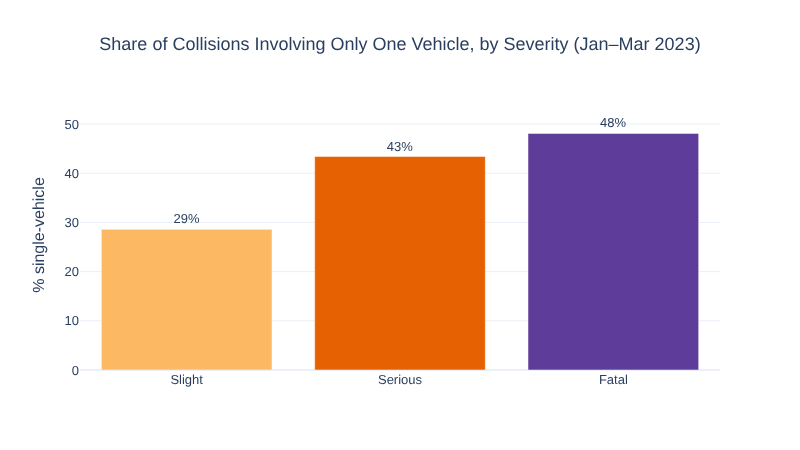

In [19]:
vehicles = df.assign(single_vehicle=df["number_of_vehicles"] == 1)
single = (vehicles.groupby("severity")["single_vehicle"].mean().mul(100).round(1)
          .reindex(SEVERITY_ORDER).reset_index(name="% single-vehicle"))
fig = px.bar(single, x="severity", y="% single-vehicle", text="% single-vehicle",
             color="severity", color_discrete_map=SEVERITY_COLOURS,
             title="Share of Collisions Involving Only One Vehicle, by Severity (Jan–Mar 2023)",
             labels={"severity": ""})
fig.update_traces(texttemplate="%{text:.0f}%", textposition="outside")
fig.update_layout(showlegend=False)
save(fig, "single_vehicle_by_severity", width=800, height=450)

**Findings**

* **48% of fatal collisions involved a single vehicle**, compared with 29% of slight ones.
* This points to loss of control and speed as factors in the most severe outcomes, rather than multi-vehicle collisions.

## 9. Where accidents happen

The map shows the density of all collisions as a heatmap, with each fatal collision marked. Click a marker for its date, road surface and weather. GitHub can't display interactive maps, so open `accident_map.html` in a browser to explore it.

In [20]:
geo = df.dropna(subset=["latitude", "longitude"])
m = folium.Map(location=[54.5, -3.0], zoom_start=6)
HeatMap(geo[["latitude", "longitude"]].round(4).values.tolist(), radius=8, blur=10,
        name="All collisions (density)").add_to(m)

fatal_layer = folium.FeatureGroup(name="Fatal collisions")
for _, row in geo[geo["fatal"]].iterrows():
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]], radius=4, color=SEVERITY_COLOURS["Fatal"],
        fill=True, fill_opacity=0.8,
        popup=f"{row['date']:%d %b %Y} · {row['surface']} road · {row['weather']}",
    ).add_to(fatal_layer)
fatal_layer.add_to(m)
folium.LayerControl().add_to(m)
m.save("accident_map.html")
print(f"Map saved: {len(geo):,} collisions in the heatmap, {int(geo['fatal'].sum())} fatal collisions marked")

Map saved: 24,493 collisions in the heatmap, 320 fatal collisions marked


In [21]:
area = severity_rates(df.assign(area=df["urban_or_rural_area"].map({1: "Urban", 2: "Rural"})), "area")
area.drop(columns=["fatal_ci_low", "fatal_ci_high"])

,collisions,serious_or_fatal,fatal,serious_or_fatal_%,fatal_%,fatal_%_95ci
area,,,,,,
Urban,16747,3457,138,20.6,0.82,0.70–0.97
Rural,7746,1986,182,25.6,2.35,2.04–2.71


**Findings**

* Collisions cluster in cities and along major roads, as expected from traffic volumes.
* **Rural collisions are far more likely to be fatal** (2.35% vs 0.82% in urban areas), almost three times the rate. This is consistent with higher speeds on rural roads.

## 10. Summary, limitations and recommendations

### Key findings
1. **Wet roads matter more than bad weather.** Collisions on wet or damp roads were almost twice as likely to be fatal as those on dry roads (1.96% vs 1.02%).
2. **Weather on its own is a weak predictor of severity.** Rain without high winds has the same severity profile as fine weather.
3. **Ice and snow are not linked to more severe collisions**, possibly because drivers slow down when the danger is visible.
4. **The most severe collisions are often single-vehicle (48% of fatal collisions) and rural** (fatal rate almost three times the urban rate).
5. **Timing follows travel patterns:** peaks at 3pm, 5pm and 8am, with Friday the busiest day.

### Limitations
* **Associations, not causes.** For example, wet roads may coincide with darkness or higher speeds on certain roads.
* **No traffic-volume data.** The data shows which collisions are *more severe*, not which conditions produce *more collisions per mile driven*.
* **One winter only.** The results cover January–March 2023, and other years may differ.
* **Police-reported collisions only.** Many slight collisions are never reported to the police, so the true share of slight collisions is likely higher.

### Recommendations for road safety teams
* Prioritise **wet-weather measures** on high-risk routes, such as skid-resistant surfacing, drainage and variable speed limits, ahead of general "bad weather" campaigns.
* Focus severity-reduction work on **rural roads and single-vehicle loss-of-control collisions**.
* **Next step for this analysis:** fit a logistic regression with surface, weather, light conditions, speed limit and urban/rural area together, to separate their effects.